# Lab 5 - NLP Intro

**Topic:** Text classification pipeline (TF‑IDF baseline → embeddings → transformer demo)  
**Designed for:** Google Colab (≈12 GB RAM)  
**Course:** Advanced Methods of Artificial Intelligence

> This is **practice labwork (not graded)**. It is meant to prepare you for Week 7’s Assignment 3, but **do not submit this notebook as an assignment**.

## Learning goals
By the end of this lab, you can:
- Turn raw text into numeric features using **Bag of Words / TF‑IDF**.
- Train a strong baseline (**TF‑IDF + Logistic Regression**) and interpret it.
- Train a simple deep model with learned **embeddings**.
- Run a **pretrained transformer** for quick inference (demo) and understand when it helps.
- Recognize common **evaluation pitfalls** in NLP (leakage, duplicates, ambiguous labels).

---


## 0) Setup (Colab-safe)

This lab is designed to avoid RAM issues:
- We keep datasets small (≈5–6k examples).
- We keep TF‑IDF feature size bounded (`max_features`).
- We keep neural models small (short sequences + small embedding).
- We avoid converting sparse matrices to dense arrays.

Run this cell first.

In [1]:
# === Imports + reproducibility ===
# We import common libraries and set random seeds.
# Setting seeds makes results more stable (two students running the notebook get similar outputs).

import os, re, textwrap, random
import numpy as np

# Optional: show approximate RAM usage (Colab usually has psutil)
try:
    import psutil
    def ram_gb():
        vm = psutil.virtual_memory()
        return vm.used / 1e9
    print(f"Approx RAM used: {ram_gb():.2f} GB")
except Exception:
    print("psutil not available (ok).")

SEED = 42
random.seed(SEED)
np.random.seed(SEED)

print("Ready.")

Approx RAM used: 3.45 GB
Ready.


## 1) Get a small real dataset: SMS Spam (ham vs spam)

We’ll use the classic **SMS Spam Collection** dataset (≈5.6k messages). It is small, fast, and works well for TF‑IDF.

If the download fails (rare), we fall back to a tiny built-in toy dataset so you can still run the notebook.

In [2]:
# === Dataset loading (small + fast) ===
# We download a tiny public dataset: SMS messages labeled as:
#   - ham  = normal message
#   - spam = unwanted / promotional / scam message
#
# If the download fails, we switch to a tiny built-in toy dataset so the notebook still runs.

import pandas as pd
from pathlib import Path
import urllib.request, zipfile

DATA_DIR = Path('data_sms')
DATA_DIR.mkdir(exist_ok=True)

url = 'https://archive.ics.uci.edu/ml/machine-learning-databases/00228/smsspamcollection.zip'
zip_path = DATA_DIR / 'smsspamcollection.zip'

try:
    if not zip_path.exists():
        print('Downloading dataset...')
        urllib.request.urlretrieve(url, zip_path)
    with zipfile.ZipFile(zip_path, 'r') as z:
        z.extractall(DATA_DIR)
    raw_path = DATA_DIR / 'SMSSpamCollection'
    df = pd.read_csv(raw_path, sep='	', header=None, names=['label', 'text'])
    print('Loaded:', df.shape)
    print(df['label'].value_counts())
except Exception as e:
    print('Download failed. Using toy fallback dataset. Error:', e)
    df = pd.DataFrame({
        'label': ['ham','ham','spam','ham','spam','ham','spam','ham'],
        'text': [
            'Hi, are we meeting today?',
            'Can you send the report by 5pm?',
            'WIN a FREE iPhone now! Click here!',
            'I will call you later.',
            'Congratulations! You have been selected for a cash prize.',
            'Lunch at 1?',
            'URGENT! Your account is suspended. Verify now.',
            'Thanks for your help.'
        ]
    })

# Binary target
y = (df['label'].str.lower() == 'spam').astype(int).values
texts = df['text'].astype(str).values

print('\nExample messages:')
for i in range(min(3, len(df))):
    print('-', df.loc[i,'label'], ':', df.loc[i,'text'][:120])

Loaded: (5572, 2)
label
ham     4825
spam     747
Name: count, dtype: int64

Example messages:
- ham : Go until jurong point, crazy.. Available only in bugis n great world la e buffet... Cine there got amore wat...
- ham : Ok lar... Joking wif u oni...
- spam : Free entry in 2 a wkly comp to win FA Cup final tkts 21st May 2005. Text FA to 87121 to receive entry question(std txt r


## 2) Minimal preprocessing (keep it simple)

For many baselines, you can get good results with **very light** cleaning.
We’ll:
- lower-case
- normalize whitespace

(We deliberately do **not** do heavy stemming/lemmatization here.)

In [3]:
# === Minimal text cleaning ===
# NLP pipelines often start with simple, safe cleaning.
# Here we ONLY:
#   1) lowercase the text
#   2) normalize whitespace
# We avoid heavy preprocessing (stemming/lemmatization) to keep the baseline easy to understand.

def clean_text(s: str) -> str:
    s = s.lower()
    s = re.sub(r'\s+', ' ', s).strip()
    return s

texts_clean = np.array([clean_text(t) for t in texts])

print('Before:', texts[0][:120])
print('After :', texts_clean[0][:120])

Before: Go until jurong point, crazy.. Available only in bugis n great world la e buffet... Cine there got amore wat...
After : go until jurong point, crazy.. available only in bugis n great world la e buffet... cine there got amore wat...


## 3) Train/test split (avoid leakage)

We split once and keep the split fixed for fair comparison.

In [4]:
# === Train/test split ===
# We evaluate models on *unseen* data.
# - train set: used to fit the model
# - test set : used only for final evaluation
#
# stratify=y keeps the spam/ham ratio similar in both splits.
# This matters because spam is usually the minority class.

from sklearn.model_selection import train_test_split

X_train_text, X_test_text, y_train, y_test = train_test_split(
    texts_clean, y, test_size=0.2, random_state=SEED, stratify=y
)

print('Train:', len(X_train_text), ' Test:', len(X_test_text))
print('Spam rate train:', y_train.mean().round(3), ' test:', y_test.mean().round(3))

Train: 4457  Test: 1115
Spam rate train: 0.134  test: 0.134


## 4) Baseline A: Bag of Words (CountVectorizer) + Logistic Regression

This is the simplest strong baseline.

**RAM safety:** keep `max_features` moderate and keep data sparse.

**Idea (in plain words):**
- We treat each message as a **bag** (multiset) of words.
- We **count** how many times each word appears.
- The result is a long numeric vector (one position per word).

**Key term:** The big table of counts is called a **document–term matrix**.
Most entries are zero → we store it as a **sparse matrix** (RAM-friendly).


BoW matrix shapes (rows = messages, columns = vocabulary words):
  Train: (4457, 3620)
  Test : (1115, 3620)
Vocabulary size: 3620

BOW baseline results
              precision    recall  f1-score   support

         ham       0.98      1.00      0.99       966
        spam       1.00      0.86      0.92       149

    accuracy                           0.98      1115
   macro avg       0.99      0.93      0.96      1115
weighted avg       0.98      0.98      0.98      1115



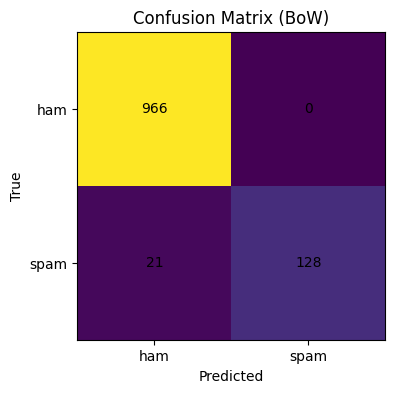


Top word-counts in the first training message (example):
  he: 1
  will: 1
  you: 1
  guys: 1
  close: 1


In [5]:
# === Baseline A: Bag of Words (BoW) + Logistic Regression ===
# 1) CountVectorizer builds a vocabulary of words.
# 2) Each message becomes a vector of word *counts*.
#    Example: "free prize" -> {free:1, prize:1, ...}
#
# RAM note: The resulting matrix is SPARSE (mostly zeros), so we keep it sparse.

from sklearn.feature_extraction.text import CountVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import classification_report, confusion_matrix
import matplotlib.pyplot as plt

# max_features limits vocabulary size (RAM/time safety)
# min_df=2 removes extremely rare words that appear in only 1 message
bow = CountVectorizer(
    max_features=20000,
    min_df=2,
)

# Fit on TRAIN only, then transform both train and test
X_train_bow = bow.fit_transform(X_train_text)
X_test_bow  = bow.transform(X_test_text)

print('BoW matrix shapes (rows = messages, columns = vocabulary words):')
print('  Train:', X_train_bow.shape)
print('  Test :', X_test_bow.shape)
print('Vocabulary size:', len(bow.get_feature_names_out()))

# Logistic Regression is a strong linear classifier for sparse text features.
# It learns a weight for each word:
#   + weight -> pushes prediction toward spam
#   - weight -> pushes prediction toward ham
clf_bow = LogisticRegression(max_iter=2000, n_jobs=None)
clf_bow.fit(X_train_bow, y_train)

pred_bow = clf_bow.predict(X_test_bow)

print()
print('BOW baseline results')
print(classification_report(y_test, pred_bow, target_names=['ham','spam']))

# Confusion matrix: shows where the model makes mistakes
# rows = true label, columns = predicted label
cm = confusion_matrix(y_test, pred_bow)
plt.figure(figsize=(4,4))
plt.imshow(cm)
plt.title('Confusion Matrix (BoW)')
plt.xlabel('Predicted')
plt.ylabel('True')
plt.xticks([0,1], ['ham','spam'])
plt.yticks([0,1], ['ham','spam'])
for (i,j), v in np.ndenumerate(cm):
    plt.text(j, i, str(v), ha='center', va='center')
plt.show()

# Quick peek: which words appear in the FIRST training message?
# We do NOT convert the whole matrix to dense (would waste RAM). We only inspect one row.
row0 = X_train_bow[0]
idx = row0.nonzero()[1]
counts = row0.data
pairs = sorted(zip(idx, counts), key=lambda x: -x[1])[:10]
vocab = bow.get_feature_names_out()
print()
print('Top word-counts in the first training message (example):')
for j, c in pairs:
    print(f'  {vocab[j]}: {int(c)}')

### Interpreting the baseline (which words push ‘spam’?)

One advantage of linear TF‑IDF/BOW models: **interpretability**. We can inspect the most influential words.

In [6]:
# === Interpreting word weights ===
# For a linear model, each word gets a coefficient (weight).
# - Large positive weight -> strongly associated with SPAM
# - Large negative weight -> strongly associated with HAM

feature_names = np.array(bow.get_feature_names_out())
coefs = clf_bow.coef_.ravel()  # positive -> spam, negative -> ham

top_pos_idx = np.argsort(coefs)[-15:][::-1]
top_neg_idx = np.argsort(coefs)[:15]

print('Top words indicating SPAM:')
print(feature_names[top_pos_idx])

print('\nTop words indicating HAM:')
print(feature_names[top_neg_idx])

Top words indicating SPAM:
['txt' 'uk' 'ringtone' 'reply' 'call' 'text' 'new' 'won' 'chat' 'service'
 '150p' 'stop' 'mobile' '50' '88066']

Top words indicating HAM:
['gt' 'lt' 'my' 'me' 'amp' 'sir' 'll' 'he' 'but' 'sorry' 'way' 'him' 'da'
 'year' 'up']


## 5) Baseline B: TF‑IDF + Logistic Regression (often the best ‘first choice’)

TF‑IDF reduces the impact of extremely common words and highlights more informative terms.

**TF‑IDF intuition:**
- **TF (term frequency):** a word is important if it appears many times in a message.
- **IDF (inverse document frequency):** a word is *less* informative if it appears in *many* messages (e.g., “the”, “and”).

So TF‑IDF gives higher weight to words that are **frequent in this message** but **rare in the whole dataset**.


In [7]:
# === Baseline B: TF-IDF + Logistic Regression ===
# TF-IDF is like BoW, but words are weighted by "importance".
# Common words across many documents get down-weighted.

from sklearn.feature_extraction.text import TfidfVectorizer

# ngram_range=(1,2) means we include:
#   - single words (unigrams)
#   - 2-word phrases (bigrams) like "call now", "free entry"
# sublinear_tf=True uses log(1 + tf) which often works well in practice.

tfidf = TfidfVectorizer(
    max_features=30000,
    ngram_range=(1,2),
    min_df=2,
    sublinear_tf=True,
)

X_train_tfidf = tfidf.fit_transform(X_train_text)
X_test_tfidf  = tfidf.transform(X_test_text)

print('TF-IDF matrix shapes:')
print('  Train:', X_train_tfidf.shape)
print('  Test :', X_test_tfidf.shape)

from sklearn.linear_model import LogisticRegression
from sklearn.metrics import classification_report

clf_tfidf = LogisticRegression(max_iter=2000)
clf_tfidf.fit(X_train_tfidf, y_train)

pred_tfidf = clf_tfidf.predict(X_test_tfidf)

print()
print('TF-IDF baseline results')
print(classification_report(y_test, pred_tfidf, target_names=['ham','spam']))

TF-IDF matrix shapes:
  Train: (4457, 12167)
  Test : (1115, 12167)

TF-IDF baseline results
              precision    recall  f1-score   support

         ham       0.97      1.00      0.98       966
        spam       1.00      0.77      0.87       149

    accuracy                           0.97      1115
   macro avg       0.98      0.88      0.92      1115
weighted avg       0.97      0.97      0.97      1115



## 6) Error analysis (small but powerful)

Looking at a few mistakes often teaches more than metrics.

In [8]:
# === Error analysis ===
# Instead of only reading metrics, we inspect a few mistakes.
# This helps us understand patterns like:
# - spam that looks polite (hard cases)
# - ham messages that contain words like "free" (false alarms)
#
# predict_proba gives a probability-like score for the spam class.

proba = clf_tfidf.predict_proba(X_test_tfidf)[:,1]
errors = np.where(pred_tfidf != y_test)[0]

print('Number of errors:', len(errors))

# Show a few false positives and false negatives
shown = 0
for idx in errors[:10]:
    true = y_test[idx]
    pred = pred_tfidf[idx]
    p = proba[idx]
    label_true = 'spam' if true==1 else 'ham'
    label_pred = 'spam' if pred==1 else 'ham'
    print('\n---')
    print(f'True={label_true} | Pred={label_pred} | P(spam)={p:.3f}')
    print(textwrap.fill(X_test_text[idx], width=100))
    shown += 1

Number of errors: 35

---
True=spam | Pred=ham | P(spam)=0.154
freemsg hey there darling it's been 3 week's now and no word back! i'd like some fun you up for it
still? tb ok! xxx std chgs to send, £1.50 to rcv

---
True=spam | Pred=ham | P(spam)=0.316
dear voucher holder 2 claim your 1st class airport lounge passes when using your holiday voucher
call 08704439680. when booking quote 1st class x 2

---
True=spam | Pred=ham | P(spam)=0.437
talk sexy!! make new friends or fall in love in the worlds most discreet text dating service. just
text vip to 83110 and see who you could meet.

---
True=spam | Pred=ham | P(spam)=0.420
sexy sexy cum and text me im wet and warm and ready for some porn! u up for some fun? this msg is
free recd msgs 150p inc vat 2 cancel text stop

---
True=spam | Pred=ham | P(spam)=0.283
hi if ur lookin 4 saucy daytime fun wiv busty married woman am free all next week chat now 2 sort
time 09099726429 janinexx calls£1/minmobsmorelkpobox177hp51fl

---
True=spam | Pred=h

## 7) Embeddings baseline (small neural model)

Now we move from **counting words** to **learning vector meanings**.

We will use a lightweight Keras model:
- `TextVectorization` → integer tokens
- `Embedding` → dense vectors
- `GlobalAveragePooling1D` → one vector per message

This is fast and usually fits easily within Colab RAM.

**Why try embeddings?**
Bag‑of‑Words/TF‑IDF treat words like *independent tokens* (they do not “understand” similarity).
Embeddings learn a **dense vector** for each token so that words used in similar contexts tend to have similar vectors.


In [9]:
# === Embeddings baseline (small neural model) ===
# Here we learn representations instead of counting words.
# Steps:
# 1) TextVectorization turns text -> integer token IDs
# 2) Embedding layer maps each token ID -> a dense vector
# 3) Pooling compresses a sequence into a single vector per message
# 4) Dense layers predict spam probability
#
# RAM safety choices:
# - MAX_TOKENS and SEQ_LEN are modest
# - embedding dimension is small (64)
# - batch size is moderate (64)

import tensorflow as tf

MAX_TOKENS = 20000   # vocabulary size cap
SEQ_LEN = 40         # max tokens per message (SMS are short)

vectorizer = tf.keras.layers.TextVectorization(
    max_tokens=MAX_TOKENS,
    output_mode='int',
    output_sequence_length=SEQ_LEN,
)

# IMPORTANT: adapt on training text only (prevents data leakage)
vectorizer.adapt(X_train_text)

# tf.data makes input pipelines efficient and memory-friendly
train_ds = (
    tf.data.Dataset.from_tensor_slices((X_train_text, y_train))
    .shuffle(2000, seed=SEED)
    .batch(64)
    .prefetch(tf.data.AUTOTUNE)
)

test_ds = (
    tf.data.Dataset.from_tensor_slices((X_test_text, y_test))
    .batch(64)
    .prefetch(tf.data.AUTOTUNE)
)

model = tf.keras.Sequential([
    vectorizer,
    tf.keras.layers.Embedding(MAX_TOKENS, 64, mask_zero=True),
    tf.keras.layers.GlobalAveragePooling1D(),
    tf.keras.layers.Dense(64, activation='relu'),
    tf.keras.layers.Dropout(0.3),
    tf.keras.layers.Dense(1, activation='sigmoid')
])

model.compile(
    optimizer='adam',
    loss='binary_crossentropy',
    metrics=['accuracy']
)

callbacks = [
    # Early stopping prevents overfitting and saves time
    tf.keras.callbacks.EarlyStopping(monitor='val_loss', patience=2, restore_best_weights=True)
]

history = model.fit(
    train_ds,
    validation_data=test_ds,
    epochs=10,
    callbacks=callbacks,
    verbose=1
)

test_loss, test_acc = model.evaluate(test_ds, verbose=0)
print(f"Neural embedding baseline — test accuracy: {test_acc:.4f}")

Epoch 1/10


/opt/homebrew/lib/python3.11/site-packages/keras/src/trainers/epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to already be shuffled (via `.shuffle(buffer_size)`).
  self.data_adapter = data_adapters.get_data_adapter(


70/70 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step - accuracy: 0.8506 - loss: nan - val_accuracy: 0.8664 - val_loss: nan
Epoch 2/10
70/70 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.8658 - loss: nan - val_accuracy: 0.8664 - val_loss: nan
Epoch 3/10
70/70 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.8658 - loss: nan - val_accuracy: 0.8664 - val_loss: nan
Neural embedding baseline — test accuracy: 0.8664


## 8) Transformer demo (pretrained model, inference only)

This is **optional** and meant as a demo of *“use existing language knowledge”*.

We will:
- install `transformers`
- run a pretrained sentiment model on a few example texts

⚠️ We are **not** fine-tuning here (fine-tuning can be slower).

**Important:** the model below is a *sentiment* model (positive/negative), not a spam detector.
We use it only to demonstrate how **pretrained transformers** can produce useful predictions without training.


In [10]:
# === Optional: Transformer demo (pretrained, inference only) ===
# This section is OPTIONAL.
# We use a pretrained transformer to show "plug-and-play" NLP:
# - No training here (training transformers can be heavy)
# - We run only a few example texts
#
# Note: This particular model is a sentiment classifier (positive/negative).
# It is NOT a spam detector. It is only a demo of the idea.

# Installing transformers usually fits Colab comfortably
!pip -q install transformers

from transformers import pipeline

# device=-1 means CPU. (GPU is also fine, but CPU is enough for 3 examples.)
sentiment = pipeline(
    'text-classification',
    model='distilbert-base-uncased-finetuned-sst-2-english',
    device=-1
)

examples = [
    "I can't recommend this — delivery was late, but support fixed it.",
    "URGENT! You have won a prize. Click the link now!",
    "Thank you for your help, the issue is solved.",
]

out = sentiment(examples)
for t, r in zip(examples, out):
    print()
    print('Text:', t)
    print('Prediction:', r)

config.json:   0%|          | 0.00/629 [00:00<?, ?B/s]

model.safetensors:   0%|          | 0.00/268M [00:00<?, ?B/s]

Loading weights:   0%|          | 0/104 [00:00<?, ?it/s]

tokenizer_config.json:   0%|          | 0.00/48.0 [00:00<?, ?B/s]

vocab.txt: 0.00B [00:00, ?B/s]


Text: I can't recommend this — delivery was late, but support fixed it.
Prediction: {'label': 'NEGATIVE', 'score': 0.7755516767501831}

Text: URGENT! You have won a prize. Click the link now!
Prediction: {'label': 'POSITIVE', 'score': 0.9889382123947144}

Text: Thank you for your help, the issue is solved.
Prediction: {'label': 'POSITIVE', 'score': 0.9997883439064026}


## 9) Evaluation pitfalls (mini-checks)

NLP evaluations can look better than reality if you’re not careful.

Two quick checks:
1) **Duplicates** — if the same message appears in train and test, accuracy inflates.
2) **Near duplicates** — spam templates often repeat with small changes.

Below is a simple duplicate check (exact matches).

In [11]:
# === Duplicate check (evaluation sanity) ===
# If the same exact text appears in both train and test, evaluation becomes optimistic.
# This simple check looks for EXACT duplicates.
# (Near-duplicates are harder; we do not compute them here to keep the lab lightweight.)

train_set = set(X_train_text.tolist())
test_set  = set(X_test_text.tolist())

overlap = train_set.intersection(test_set)
print('Exact duplicates across train/test:', len(overlap))

if len(overlap) > 0:
    print('Example duplicate:')
    print(next(iter(overlap))[:200])
else:
    print('Good: no exact duplicates found across the split.')

Exact duplicates across train/test: 117
Example duplicate:
storming msg: wen u lift d phne, u say "hello" do u knw wt is d real meaning of hello?? . . . it's d name of a girl..! . . . yes.. and u knw who is dat girl?? "margaret hello" she is d girlfrnd f grah


## 10) Practice tasks (not graded)

Try these small modifications. They are designed to be safe for Colab RAM.

1) **Vectorizer choices**: In TF‑IDF, try `ngram_range=(1,1)` vs `(1,2)` and compare results.
2) **Stop words**: In TF‑IDF, add `stop_words='english'` and see what changes.
3) **Model choice**: Replace Logistic Regression with Linear SVM (`sklearn.svm.LinearSVC`).
4) **Threshold tuning**: Instead of default 0.5, choose a threshold that reduces false positives.
5) **Neural model**: Increase `SEQ_LEN` from 40 to 80. Does performance change? Does runtime change?

> Keep notes: What improved accuracy? What improved *business usefulness* (e.g., fewer false alarms)?

---
### Clean exit
If you ran the transformer demo and want to reduce disk usage, you can restart the runtime (optional).

In [12]:
# Optional: save the TF-IDF baseline for later reuse (not required)
# import joblib
# joblib.dump((tfidf, clf_tfidf), 'tfidf_logreg_sms.joblib')
# print('Saved model to tfidf_logreg_sms.joblib')